# Import

In [147]:
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display

# Đọc data

In [148]:
# Đọc lại đúng các file đã lưu từ notebook 01, không dùng biến cũ trong kernel.
DATA_DIR = Path("04_output/02_clean_data")
X_train_model = pd.read_pickle(DATA_DIR / "X_train_model.pkl")
X_test_model = pd.read_pickle(DATA_DIR / "X_test_model.pkl")
y_train = pd.read_pickle(DATA_DIR / "y_train.pkl")
y_test = pd.read_pickle(DATA_DIR / "y_test.pkl")
arm_train = pd.read_pickle(DATA_DIR / "arm_train.pkl")
arm_test = pd.read_pickle(DATA_DIR / "arm_test.pkl")

OUT_DIR = Path("04_output/03_association_classification")
OUT_DIR.mkdir(parents=True, exist_ok=True)

selected_features = X_train_model.columns.tolist()
RANDOM_STATE = 42

print("Đọc từ:", DATA_DIR)
print("Train/Test:", X_train_model.shape, X_test_model.shape)
print("Tỷ lệ attack:", round(y_train.mean(), 4), "/", round(y_test.mean(), 4))


Đọc từ: 04_output/02_clean_data
Train/Test: (1468182, 30) (367046, 30)
Tỷ lệ attack: 0.2406 / 0.2406


# Khai phá luật kết hợp

In [149]:
MINING_SIZE = 30_000
MIN_SUPPORT = 0.02
MIN_CONFIDENCE = 0.55

# Chọn một nhóm cột đã rời rạc hóa ở notebook 01.
preferred_cols = [
    "bwd_pkt_len_mean", "pkt_len_max", "flag_ack", "dst_port",
    "bytes_per_s", "flag_SYN", "ip_prot", "iat_max",
]
arm_cols = [col for col in preferred_cols if col in selected_features]
if len(arm_cols) < 5:
    arm_cols = [col for col in selected_features if col in arm_train.columns][:8]
if len(arm_cols) < 5:
    raise ValueError("Cần ít nhất 5 thuộc tính rời rạc hóa để khai phá luật.")

if len(y_train) > MINING_SIZE:
    mining_idx, _ = train_test_split(
        y_train.index, train_size=MINING_SIZE,
        stratify=y_train, random_state=RANDOM_STATE,
    )
else:
    mining_idx = y_train.index

basket = arm_train.loc[mining_idx, arm_cols]
transactions = [
    frozenset([*row, f"class={int(label)}"])
    for row, label in zip(basket.astype(str).itertuples(index=False, name=None),
                          y_train.loc[mining_idx])
]
MIN_COUNT = int(np.ceil(MIN_SUPPORT * len(transactions)))

print("Thuộc tính giao dịch:", arm_cols)
print("Số giao dịch:", len(transactions), "| Ngưỡng support:", MIN_COUNT)

Thuộc tính giao dịch: ['bwd_pkt_len_mean', 'pkt_len_max', 'flag_ack', 'bytes_per_s', 'flag_SYN', 'iat_max']
Số giao dịch: 30000 | Ngưỡng support: 600


## Apriori

In [150]:
def make_vertical(rows):
    vertical = defaultdict(set)
    for tid, row in enumerate(rows):
        for item in row:
            vertical[item].add(tid)
    return dict(vertical)


def matching_tids(items, vertical):
    sets = [vertical[item] for item in items]
    if not sets:
        return set()
    result = sets[0].copy()
    for tids in sets[1:]:
        result.intersection_update(tids)
    return result


def apriori(vertical, min_count, max_len=3):
    # Sinh ứng viên từ tập phổ biến ở mức trước, rồi tỉa bằng tính chất Apriori.
    level = {frozenset([item]): len(tids)
             for item, tids in vertical.items() if len(tids) >= min_count}
    frequent = level.copy()
    for size in range(2, max_len + 1):
        previous = set(level)
        candidates = set()
        for left, right in combinations(sorted(previous, key=lambda s: tuple(sorted(s))), 2):
            candidate = left | right
            if len(candidate) != size:
                continue
            if all(frozenset(part) in previous for part in combinations(candidate, size - 1)):
                candidates.add(candidate)
        level = {}
        for candidate in candidates:
            count = len(matching_tids(candidate, vertical))
            if count >= min_count:
                level[candidate] = count
        frequent.update(level)
        if not level:
            break
    return frequent


vertical = make_vertical(transactions)
sets_apriori = apriori(vertical, MIN_COUNT)
print("Số tập mục phổ biến Apriori:", len(sets_apriori))

Số tập mục phổ biến Apriori: 604


## FP-Growth

In [151]:
class FPNode:
    def __init__(self, item=None, count=0, parent=None):
        self.item = item
        self.count = count
        self.parent = parent
        self.children = {}


def build_fp_tree(weighted_rows, min_count):
    counts = Counter()
    for row, weight in weighted_rows:
        for item in row:
            counts[item] += weight
    frequent = {item: n for item, n in counts.items() if n >= min_count}
    root = FPNode()
    header = defaultdict(list)

    for row, weight in weighted_rows:
        ordered = sorted((item for item in row if item in frequent),
                         key=lambda item: (-frequent[item], item))
        node = root
        for item in ordered:
            if item not in node.children:
                node.children[item] = FPNode(item, parent=node)
                header[item].append(node.children[item])
            node = node.children[item]
            node.count += weight
    return header, frequent


def fp_growth(rows, min_count, max_len=3):
    frequent_sets = {}

    def mine(weighted_rows, prefix):
        header, counts = build_fp_tree(weighted_rows, min_count)
        for item in sorted(counts, key=lambda key: (counts[key], key)):
            pattern = prefix | {item}
            frequent_sets[frozenset(pattern)] = counts[item]
            if len(pattern) == max_len:
                continue
            conditional = []
            for node in header[item]:
                path = []
                parent = node.parent
                while parent is not None and parent.item is not None:
                    path.append(parent.item)
                    parent = parent.parent
                if path:
                    conditional.append((frozenset(path), node.count))
            if conditional:
                mine(conditional, pattern)

    mine([(row, 1) for row in rows], frozenset())
    return frequent_sets


sets_fp = fp_growth(transactions, MIN_COUNT)
print("Số tập mục phổ biến FP-Growth:", len(sets_fp))
print("Hai thuật toán cho cùng tập mục và support:", sets_apriori == sets_fp)


Số tập mục phổ biến FP-Growth: 604
Hai thuật toán cho cùng tập mục và support: True


## CHARM (tập mục đóng)

Bản CHARM rút gọn dùng tidset và bốn quan hệ giữa các tidset để tìm tập mục đóng. Giới hạn tiền tố tìm kiếm ở 3 item vì luật cần tối đa 2 điều kiện và 1 nhãn; closure có thể dài hơn 3 item. Không dùng diffset/hash tối ưu của [bài báo gốc](https://www.cs.rpi.edu/~zaki/PaperDir/TKDE05-charm.pdf).

In [152]:
def charm_closed(vertical, min_count, max_prefix_len=3):
    nodes = [
        (frozenset([item]), tids.copy())
        for item, tids in vertical.items()
        if len(tids) >= min_count
    ]
    closed = {}

    def extend(nodes):
        nodes.sort(key=lambda pair: (len(pair[1]), tuple(sorted(pair[0]))))
        i = 0
        while i < len(nodes):
            xi, ti = nodes[i]
            children = []
            j = i + 1
            while j < len(nodes):
                xj, tj = nodes[j]
                both = ti & tj
                if len(both) < min_count:
                    j += 1
                    continue

                merged = xi | xj
                if ti == tj:
                    # Hai tập xuất hiện trên đúng cùng giao dịch.
                    xi = merged
                    children = [(x | xj, t) for x, t in children]
                    nodes.pop(j)
                elif ti < tj:
                    # Mọi giao dịch có xi cũng có xj.
                    xi = merged
                    children = [(x | xj, t) for x, t in children]
                    j += 1
                elif ti > tj:
                    if len(merged) <= max_prefix_len:
                        children.append((merged, both))
                    nodes.pop(j)
                else:
                    if len(merged) <= max_prefix_len:
                        children.append((merged, both))
                    j += 1

            closure = frozenset(xi | {
                item for item, tids in vertical.items() if ti <= tids
            })
            closed[closure] = len(ti)
            if children:
                extend(children)
            i += 1

    extend(nodes)
    return closed


sets_charm = charm_closed(vertical, MIN_COUNT)
print("Số tập mục đóng CHARM:", len(sets_charm))

Số tập mục đóng CHARM: 465


## Chọn 3 luật mỗi phương pháp

In [155]:
def candidate_rules(itemsets, vertical, n):
    base_attack = len(vertical["class=1"]) / n
    rows = []
    for pattern, count in itemsets.items():
        if "class=1" not in pattern or "class=0" in pattern:
            continue
        antecedent = pattern - {"class=1"}
        if not 1 <= len(antecedent) <= 2:
            continue
        tids = matching_tids(antecedent, vertical)
        confidence = count / len(tids)
        lift = confidence / base_attack
        if confidence >= MIN_CONFIDENCE and lift > 1:
            rows.append({
                "antecedent": antecedent, "tids": tids,
                "support": count / n, "coverage": len(tids) / n,
                "confidence": confidence, "lift": lift,
            })
    return rows


def select_three(candidates):
    selected = []
    covered = set()
    remaining = candidates.copy()
    while remaining and len(selected) < 3:
        best = max(remaining, key=lambda row: (
            len(row["tids"] - covered),
            row["confidence"], row["lift"], tuple(sorted(row["antecedent"])),
        ))
        selected.append(best)
        covered.update(best["tids"])
        remaining.remove(best)
    if len(selected) < 3:
        raise ValueError("Chưa có đủ 3 luật attack. Giảm MIN_SUPPORT hoặc MIN_CONFIDENCE rồi chạy lại trên train.")
    return selected


rules_apriori = select_three(candidate_rules(sets_apriori, vertical, len(transactions)))
rules_fp = select_three(candidate_rules(sets_fp, vertical, len(transactions)))
rules_charm = select_three(candidate_rules(sets_charm, vertical, len(transactions)))


def rule_flags(items, rules):
    flags = pd.DataFrame(index=items.index)
    for i, rule in enumerate(rules, 1):
        match = pd.Series(True, index=items.index)
        for item in rule["antecedent"]:
            col = item.split("=", 1)[0]
            match &= items[col].astype(str).eq(item)
        flags[f"Rule_{i}"] = match.astype("int8")
    return flags


def describe_rules(rules, method, items, labels):
    flags = rule_flags(items, rules)
    base_attack = labels.mean()
    rows = []
    for i, rule in enumerate(rules, 1):
        mask = flags[f"Rule_{i}"].astype(bool)
        coverage = mask.mean()
        support = (mask & labels.eq(1)).mean()
        confidence = support / coverage if coverage else 0
        rows.append({
            "Phương pháp": method, "Luật": f"Rule_{i}",
            "Tiền đề": " & ".join(sorted(rule["antecedent"])),
            "Kết luận": "attack", "Coverage": coverage,
            "Support": support, "Confidence": confidence,
            "Lift": confidence / base_attack,
        })
    return pd.DataFrame(rows), flags


table_apriori, flags_train_apriori = describe_rules(rules_apriori, "Apriori", arm_train, y_train)
table_fp, flags_train_fp = describe_rules(rules_fp, "FP-Growth", arm_train, y_train)
table_charm, flags_train_charm = describe_rules(rules_charm, "CHARM", arm_train, y_train)
rules_table = pd.concat([table_apriori, table_fp, table_charm], ignore_index=True)
display(rules_table.round(4))
rules_table.to_csv("04_output/03_association_classification/association_rules.csv", index=False)

,Phương pháp,Luật,Tiền đề,Kết luận,Coverage,Support,Confidence,Lift
0,Apriori,Rule_1,bwd_pkt_len_mean=Q4,attack,0.2500,0.1423,0.5692,2.3655
1,Apriori,Rule_2,bwd_pkt_len_mean=Q1 & bytes_per_s=Q1,attack,0.1615,0.0957,0.5926,2.4626
2,Apriori,Rule_3,iat_max=Q1 & pkt_len_max=Q1,attack,0.1475,0.0868,0.5886,2.4461
3,FP-Growth,Rule_1,bwd_pkt_len_mean=Q4,attack,0.2500,0.1423,0.5692,2.3655
4,FP-Growth,Rule_2,bwd_pkt_len_mean=Q1 & bytes_per_s=Q1,attack,0.1615,0.0957,0.5926,2.4626
5,FP-Growth,Rule_3,iat_max=Q1 & pkt_len_max=Q1,attack,0.1475,0.0868,0.5886,2.4461
6,CHARM,Rule_1,bwd_pkt_len_mean=Q4,attack,0.2500,0.1423,0.5692,2.3655
7,CHARM,Rule_2,bwd_pkt_len_mean=Q1 & bytes_per_s=Q1,attack,0.1615,0.0957,0.5926,2.4626
8,CHARM,Rule_3,pkt_len_max=Q4,attack,0.2421,0.1423,0.5875,2.4416


## Truy vết từng lượt chọn luật

Chọn luật phủ thêm nhiều giao dịch train nhất. Confidence và lift chỉ dùng để phá hòa; bảng ghi độ phủ tăng thêm và độ phủ chung sau mỗi lượt.


In [156]:
trace_rows = []
for method, rules in [
    ("Apriori", rules_apriori),
    ("FP-Growth", rules_fp),
    ("CHARM", rules_charm),
]:
    covered = set()
    for turn, rule in enumerate(rules, 1):
        new_tids = rule["tids"] - covered
        covered.update(rule["tids"])
        consequent = rule.get("consequent", "attack").removeprefix("class=")
        trace_rows.append({
            "Phương pháp": method,
            "Lượt": turn,
            "Luật chọn": " & ".join(sorted(rule["antecedent"])) + " ⇒ " + consequent,
            "Phủ thêm (%)": 100 * len(new_tids) / len(transactions),
            "Phủ chung sau lượt (%)": 100 * len(covered) / len(transactions),
            "Confidence": rule["confidence"],
            "Lift": rule["lift"],
        })

selection_trace = pd.DataFrame(trace_rows)
display(selection_trace.round(3))
selection_trace.to_csv("04_output/03_association_classification/rule_selection_trace.csv", index=False)


,Phương pháp,Lượt,Luật chọn,Phủ thêm (%),Phủ chung sau lượt (%),Confidence,Lift
0,Apriori,1,bwd_pkt_len_mean=Q4 ⇒ attack,24.953,24.953,0.564,2.345
1,Apriori,2,bwd_pkt_len_mean=Q1 & bytes_per_s=Q1 ⇒ attack,16.303,41.257,0.597,2.480
2,Apriori,3,iat_max=Q1 & pkt_len_max=Q1 ⇒ attack,6.053,47.310,0.593,2.465
3,FP-Growth,1,bwd_pkt_len_mean=Q4 ⇒ attack,24.953,24.953,0.564,2.345
4,FP-Growth,2,bwd_pkt_len_mean=Q1 & bytes_per_s=Q1 ⇒ attack,16.303,41.257,0.597,2.480
5,FP-Growth,3,iat_max=Q1 & pkt_len_max=Q1 ⇒ attack,6.053,47.310,0.593,2.465
6,CHARM,1,bwd_pkt_len_mean=Q4 ⇒ attack,24.953,24.953,0.564,2.345
7,CHARM,2,bwd_pkt_len_mean=Q1 & bytes_per_s=Q1 ⇒ attack,16.303,41.257,0.597,2.480
8,CHARM,3,pkt_len_max=Q4 ⇒ attack,3.120,44.377,0.578,2.402


## Bảng nội dung luật và đối chiếu ba phương pháp

Mỗi dòng viết rõ điều kiện và kết luận. Bảng đối chiếu đếm luật trùng theo cả tiền đề và kết luận; “cùng bộ” không phụ thuộc thứ tự Rule_1/2/3.

`Q1`–`Q4` là các nhóm tứ phân vị tạo từ train. `Rule_i=1` khi tiền đề đúng; không dùng kết luận thật để tạo cột này.


In [157]:
rule_expressions = rules_table[["Phương pháp", "Luật", "Tiền đề", "Kết luận"]].copy()
rule_expressions["Luật kết hợp"] = (
    rule_expressions["Tiền đề"] + " ⇒ " + rule_expressions["Kết luận"]
)
rule_expressions = rule_expressions[["Phương pháp", "Luật", "Luật kết hợp"]]
display(rule_expressions)
rule_expressions.to_csv("04_output/03_association_classification/rule_expressions.csv", index=False)


,Phương pháp,Luật,Luật kết hợp
0,Apriori,Rule_1,bwd_pkt_len_mean=Q4 ⇒ attack
1,Apriori,Rule_2,bwd_pkt_len_mean=Q1 & bytes_per_s=Q1 ⇒ attack
2,Apriori,Rule_3,iat_max=Q1 & pkt_len_max=Q1 ⇒ attack
3,FP-Growth,Rule_1,bwd_pkt_len_mean=Q4 ⇒ attack
4,FP-Growth,Rule_2,bwd_pkt_len_mean=Q1 & bytes_per_s=Q1 ⇒ attack
5,FP-Growth,Rule_3,iat_max=Q1 & pkt_len_max=Q1 ⇒ attack
6,CHARM,Rule_1,bwd_pkt_len_mean=Q4 ⇒ attack
7,CHARM,Rule_2,bwd_pkt_len_mean=Q1 & bytes_per_s=Q1 ⇒ attack
8,CHARM,Rule_3,pkt_len_max=Q4 ⇒ attack


In [158]:
method_order = ["Apriori", "FP-Growth", "CHARM"]
method_rules = {}
for method in method_order:
    rows = rules_table.loc[
        rules_table["Phương pháp"] == method, ["Tiền đề", "Kết luận"]
    ]
    method_rules[method] = list(rows.itertuples(index=False, name=None))

comparison_rows = []
for left, right in combinations(method_order, 2):
    left_rules = method_rules[left]
    right_rules = method_rules[right]
    common = len(set(left_rules) & set(right_rules))
    comparison_rows.append({
        "So sánh": f"{left} / {right}",
        "Số luật trùng": f"{common}/3",
        "Cùng bộ 3 luật": "Có" if set(left_rules) == set(right_rules) else "Không",
        "Cùng thứ tự": "Có" if left_rules == right_rules else "Không",
    })

rule_comparison = pd.DataFrame(comparison_rows)
display(rule_comparison)
rule_comparison.to_csv("04_output/03_association_classification/rule_comparison.csv", index=False)


,So sánh,Số luật trùng,Cùng bộ 3 luật,Cùng thứ tự
0,Apriori / FP-Growth,3/3,Có,Có
1,Apriori / CHARM,2/3,Không,Không
2,FP-Growth / CHARM,2/3,Không,Không


## So sánh coverage của ba phương pháp

In [159]:
coverage_table = pd.DataFrame([
    {
        "Phương pháp": method,
        "Luật 1 (%)": 100 * flags["Rule_1"].mean(),
        "Luật 2 (%)": 100 * flags["Rule_2"].mean(),
        "Luật 3 (%)": 100 * flags["Rule_3"].mean(),
        "Độ phủ chung (%)": 100 * flags.any(axis=1).mean(),
    }
    for method, flags in [
        ("Apriori", flags_train_apriori),
        ("FP-Growth", flags_train_fp),
        ("CHARM", flags_train_charm),
    ]
])
display(coverage_table.round(2))
coverage_table.to_csv(OUT_DIR / "rule_coverage.csv", index=False)

# Apriori và FP-Growth có thể chọn cùng luật vì cùng tìm mọi tập phổ biến.
# CHARM chỉ xét tập đóng: coverage khác là do phạm vi luật ứng viên khác,
# không có nghĩa thuật toán luôn tốt hơn trên mọi dữ liệu.

,Phương pháp,Luật 1 (%),Luật 2 (%),Luật 3 (%),Độ phủ chung (%)
0,Apriori,25.0,16.15,14.75,47.21
1,FP-Growth,25.0,16.15,14.75,47.21
2,CHARM,25.0,16.15,24.21,44.10


# Tạo thuộc tính từ luật

In [160]:
chosen_method = coverage_table.sort_values(
    ["Độ phủ chung (%)", "Phương pháp"], ascending=[False, True]
).iloc[0]["Phương pháp"]
rules_by_method = {
    "Apriori": rules_apriori,
    "FP-Growth": rules_fp,
    "CHARM": rules_charm,
}
chosen_rules = rules_by_method[chosen_method]
print("Phương pháp dùng tạo thuộc tính:", chosen_method)

# Cùng một tập con train cho D0 và D1 để việc so sánh công bằng và máy dễ chạy.
MODEL_TRAIN_SIZE = 120_000
if len(y_train) > MODEL_TRAIN_SIZE:
    model_idx, _ = train_test_split(
        y_train.index, train_size=MODEL_TRAIN_SIZE,
        stratify=y_train, random_state=RANDOM_STATE,
    )
else:
    model_idx = y_train.index

X_train_d0 = X_train_model.loc[model_idx].copy()
X_test_d0 = X_test_model.copy()
y_train_fit = y_train.loc[model_idx]

train_flags = rule_flags(arm_train.loc[model_idx, arm_cols], chosen_rules)
test_flags = rule_flags(arm_test[arm_cols], chosen_rules)
X_train_d1 = X_train_d0.join(train_flags)
X_test_d1 = X_test_d0.join(test_flags)


print("D0 train/test:", X_train_d0.shape, X_test_d0.shape)
print("D1 train/test:", X_train_d1.shape, X_test_d1.shape)


Phương pháp dùng tạo thuộc tính: Apriori
D0 train/test: (120000, 30) (367046, 30)
D1 train/test: (120000, 33) (367046, 33)


## Ba cột luật bổ sung lấy từ phương pháp đã chọn


In [162]:
selected_rule_map = rule_expressions.loc[
    rule_expressions["Phương pháp"] == chosen_method,
    ["Luật", "Luật kết hợp"],
].reset_index(drop=True)
display(selected_rule_map)
selected_rule_map.to_csv(OUT_DIR / "selected_rule_features.csv", index=False)


,Luật,Luật kết hợp
0,Rule_1,bwd_pkt_len_mean=Q4 ⇒ attack
1,Rule_2,bwd_pkt_len_mean=Q1 & bytes_per_s=Q1 ⇒ attack
2,Rule_3,iat_max=Q1 & pkt_len_max=Q1 ⇒ attack


## Ví dụ D1: thuộc tính đã tiền xử lý và ba cột luật


In [163]:
# Hiển thị các cột gốc xuất hiện trong ba tiền đề, cạnh ba cột luật mới.
rule_cols = ["Rule_1", "Rule_2", "Rule_3"]
source_cols = sorted({
    item.split("=", 1)[0]
    for rule in chosen_rules
    for item in rule["antecedent"]
})
# Lấy vài dòng thỏa từng luật và vài dòng không thỏa luật nào.
example_idx = []
for col in rule_cols:
    example_idx.extend(X_train_d1.index[X_train_d1[col].eq(1)][:2])
example_idx.extend(X_train_d1.index[X_train_d1[rule_cols].eq(0).all(axis=1)][:2])
example_idx = list(dict.fromkeys(example_idx))
d1_example = X_train_d1.loc[example_idx, source_cols + rule_cols]
display(d1_example)
d1_example.to_csv(OUT_DIR / "d1_example.csv", index=True)


,bwd_pkt_len_mean,bytes_per_s,iat_max,pkt_len_max,Rule_1,Rule_2,Rule_3
1478647,1932.500000,8.159978e+04,134174.0,4344.0,1,0,0
441691,2319.000000,1.717332e+05,66445.0,7215.0,1,0,0
1154438,41.823529,1.910500e+01,10026019.0,856.0,0,1,0
926846,41.000000,4.702697e+01,3344154.0,45.0,0,1,0
1756319,50.000000,7.850467e+05,210.0,50.0,0,0,1
1805718,65.000000,1.065421e+06,119.0,65.0,0,0,1
396290,134.000000,2.532483e+03,69497.0,134.0,0,0,0
1018120,76.000000,1.317073e+06,112.0,76.0,0,0,0


# Phân lớp

In [164]:
def build_models():
    return {
        "Logistic Regression": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=500, random_state=RANDOM_STATE)
        ),
        "Decision Tree": DecisionTreeClassifier(
            max_depth=12, min_samples_leaf=20, random_state=RANDOM_STATE
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=80, max_depth=16, min_samples_leaf=10,
            n_jobs=-1, random_state=RANDOM_STATE,
        ),
    }


results_rows = []
confusion_rows = []
for dataset, X_fit, X_eval in [
    ("D0", X_train_d0, X_test_d0),
    ("D1", X_train_d1, X_test_d1),
]:
    for name, model in build_models().items():
        print("Đang chạy:", dataset, name)
        model.fit(X_fit, y_train_fit)
        pred = model.predict(X_eval)
        results_rows.append({
            "Bộ dữ liệu": dataset, "Mô hình": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision (attack)": precision_score(y_test, pred, zero_division=0),
            "Recall (attack)": recall_score(y_test, pred, zero_division=0),
            "F1 (attack)": f1_score(y_test, pred, zero_division=0),
        })
        matrix = confusion_matrix(y_test, pred, labels=[0, 1])
        confusion_rows.append({
            "Bộ dữ liệu": dataset, "Mô hình": name,
            "TN": int(matrix[0, 0]), "FP": int(matrix[0, 1]),
            "FN": int(matrix[1, 0]), "TP": int(matrix[1, 1]),
        })

results = pd.DataFrame(results_rows)
confusion_table = pd.DataFrame(confusion_rows)
results.to_csv("04_output/03_association_classification/classification_results.csv", index=False)
confusion_table.to_csv("04_output/03_association_classification/confusion_matrices.csv", index=False)

Đang chạy: D0 Logistic Regression
Đang chạy: D0 Decision Tree
Đang chạy: D0 Random Forest
Đang chạy: D1 Logistic Regression
Đang chạy: D1 Decision Tree
Đang chạy: D1 Random Forest


## Confusion matrix

Mỗi ô ghi **số luồng** và **tỷ lệ theo nhãn thực tế**. Hai hàng trên hình là D0 và D1; ba cột là ba mô hình. Nhìn các ô FP/FN để thấy những lỗi mà Accuracy tổng thể có thể che đi.

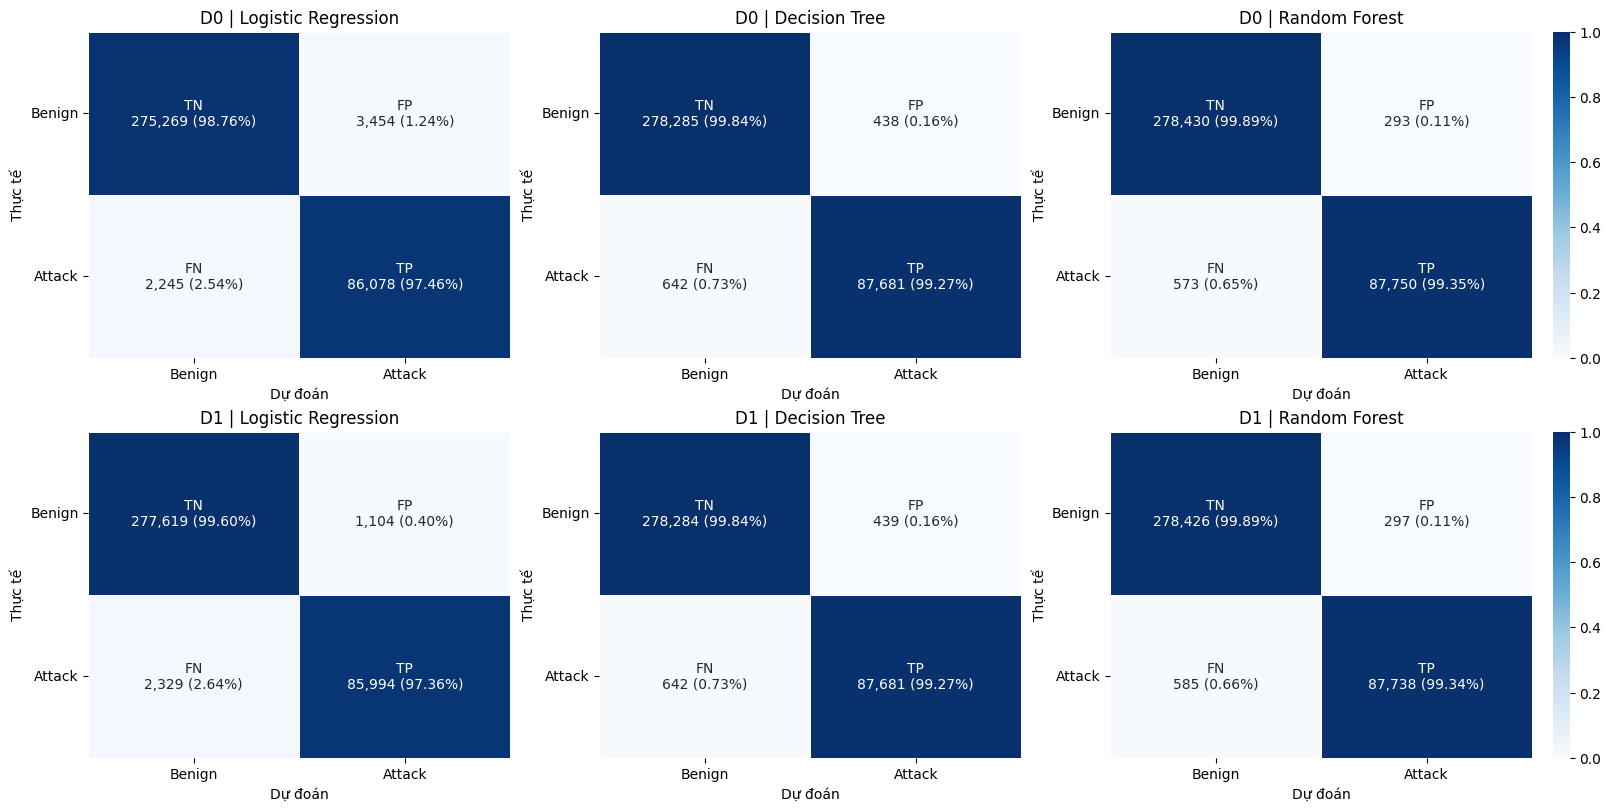

In [165]:
model_order = results["Mô hình"].drop_duplicates().tolist()
fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)

for row, dataset in enumerate(["D0", "D1"]):
    for col, model_name in enumerate(model_order):
        record = confusion_table.loc[
            (confusion_table["Bộ dữ liệu"] == dataset)
            & (confusion_table["Mô hình"] == model_name)
        ].iloc[0]
        matrix = np.array([
            [record["TN"], record["FP"]],
            [record["FN"], record["TP"]],
        ], dtype=int)
        ratio = matrix / matrix.sum(axis=1, keepdims=True)
        names = [["TN", "FP"], ["FN", "TP"]]
        labels = np.array([
            [f"{names[i][j]}\n{matrix[i, j]:,} ({ratio[i, j]:.2%})" for j in range(2)]
            for i in range(2)
        ])

        sns.heatmap(
            ratio, ax=axes[row, col], annot=labels, fmt="",
            cmap="Blues", vmin=0, vmax=1, linewidths=.5,
            linecolor="white", cbar=(col == 2),
            annot_kws={"fontsize": 10},
            xticklabels=["Benign", "Attack"],
            yticklabels=["Benign", "Attack"],
        )
        axes[row, col].set_title(f"{dataset} | {model_name}")
        axes[row, col].set_xlabel("Dự đoán")
        axes[row, col].set_ylabel("Thực tế")
        axes[row, col].tick_params(axis="y", rotation=0)

plt.savefig("04_output/03_association_classification/confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

## So sánh Precision, Recall, F1 và Accuracy

In [166]:
metric_cols = ["Accuracy", "Precision (attack)", "Recall (attack)", "F1 (attack)"]
score_table = results.sort_values(["Mô hình", "Bộ dữ liệu"]).copy()
for col in metric_cols:
    score_table[col] = score_table[col].map(lambda value: f"{value * 100:.3f}%")
display(score_table)

,Bộ dữ liệu,Mô hình,Accuracy,Precision (attack),Recall (attack),F1 (attack)
1,D0,Decision Tree,99.706%,99.503%,99.273%,99.388%
4,D1,Decision Tree,99.705%,99.502%,99.273%,99.387%
0,D0,Logistic Regression,98.447%,96.142%,97.458%,96.796%
3,D1,Logistic Regression,99.065%,98.732%,97.363%,98.043%
2,D0,Random Forest,99.764%,99.667%,99.351%,99.509%
5,D1,Random Forest,99.760%,99.663%,99.338%,99.500%


## D1 thay đổi bao nhiêu so với D0?

`Δ = D1 − D0`, đơn vị **điểm phần trăm**. Dấu `+` là tăng, dấu `−` là giảm. Bảng bên dưới giữ ba chữ số thập phân để không hiện `-0.0`.

In [167]:
model_order = results["Mô hình"].drop_duplicates().tolist()
d0 = results[results["Bộ dữ liệu"] == "D0"].set_index("Mô hình")
d1 = results[results["Bộ dữ liệu"] == "D1"].set_index("Mô hình")

effect = pd.DataFrame({"Mô hình": model_order})
for metric in metric_cols:
    effect[f"Δ {metric} (điểm %)"] = (
        d1.loc[model_order, metric].to_numpy()
        - d0.loc[model_order, metric].to_numpy()
    ) * 100

effect_display = effect.copy()
for col in effect.columns[1:]:
    effect_display[col] = effect_display[col].map(
        lambda value: "0.000" if abs(value) < .0005 else f"{value:+.3f}"
    )
display(effect_display)
effect.to_csv("04_output/03_association_classification/rule_feature_effect.csv", index=False)

,Mô hình,Δ Accuracy (điểm %),Δ Precision (attack) (điểm %),Δ Recall (attack) (điểm %),Δ F1 (attack) (điểm %)
0,Logistic Regression,+0.617,+2.590,-0.095,+1.247
1,Decision Tree,0.000,-0.001,0.000,-0.001
2,Random Forest,-0.004,-0.005,-0.014,-0.009


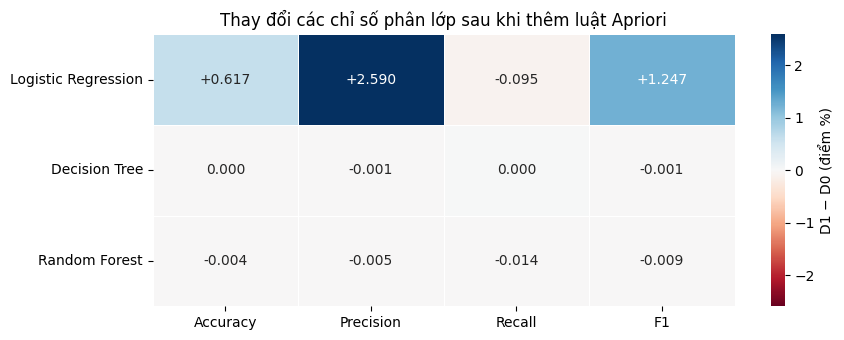

In [168]:
delta = effect.set_index("Mô hình")
delta.columns = ["Accuracy", "Precision", "Recall", "F1"]
values = delta.to_numpy()
limit = np.abs(values).max()
annotations = np.array([
    ["0.000" if abs(value) < .0005 else f"{value:+.3f}" for value in row]
    for row in values
])

fig, ax = plt.subplots(figsize=(9, 3.5))
sns.heatmap(
    delta, annot=annotations, fmt="", cmap="RdBu", center=0,
    vmin=-limit, vmax=limit, linewidths=.5, linecolor="white",
    cbar_kws={"label": "D1 − D0 (điểm %)"}, ax=ax,
)
ax.set_title(f"Thay đổi các chỉ số phân lớp sau khi thêm luật {chosen_method}")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("04_output/03_association_classification/metric_changes.png", dpi=160, bbox_inches="tight")
plt.show()